# Evaluación, transferencia y límites: estado del arte

**Nivel:** 3  
**Requisitos previos:** Evaluación, transferencia y límites nivel 1  
**Tiempo de lectura:** 25 minutos

**Pregunta:** ¿Cómo se compara la referencia aprendida más fuerte con la política protegida en una tarea C01 idéntica?


## Objetivos

Para el nivel 3 de evaluación y transferencia en C01, Reconstruye cómo una afirmación científica depende de la identidad de las trazas, los denominadores, las familias de tareas y las particiones de transferencia. Para el nivel 3 de evaluación y transferencia en C01, Una ejecución por caso ilustra un método; Para el nivel 3 de evaluación y transferencia en C01, las conclusiones de fiabilidad dependen de la matriz auditada completa y siguen limitadas a sus tareas diseñadas.


## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
Para el nivel 3 de evaluación y transferencia en C01, El notebook lee artefactos comprometidos del producto. Para el nivel 3 de evaluación y transferencia en C01, Propietario: Para el nivel 3 de evaluación y transferencia en C01, Neuraxis. Para el nivel 3 de evaluación y transferencia en C01, Repositorio: Para el nivel 3 de evaluación y transferencia en C01, https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Para el nivel 3 de evaluación y transferencia en C01, Apache-2.0. Para el nivel 3 de evaluación y transferencia en C01, El JSON es un artefacto experimental propio y congelado; Para el nivel 3 de evaluación y transferencia en C01, este notebook no redistribuye datos de benchmarks externos.

Para el nivel 3 de evaluación y transferencia en C01, Este notebook lee `data/derived/index.json` y las trazas listadas. Para el nivel 3 de evaluación y transferencia en C01, La ejecución usa un espacio aislado de caso Reflexmesh. Para el nivel 3 de evaluación y transferencia en C01, Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta. Para el nivel 3 de evaluación y transferencia en C01, El manifiesto de publicación verifica los hashes. Para el nivel 3 de evaluación y transferencia en C01, M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado.

Para el nivel 3 de evaluación y transferencia en C01, Artefactos de esta lección:

- `data/derived/index.json`
- `data/derived/benchmark-adequacy.json`
- `data/derived/research.json`
- `data/derived/semantic-transfer/index.json`
- `data/derived/semantic-transfer/report.json`
- `data/derived/episodes/M01-C01-nominal-40000.json`
- `data/derived/episodes/M04-C01-nominal-40000.json`
- `data/derived/episodes/M09-C01-nominal-40000.json`
- `data/derived/episodes/M12-C01-nominal-40000.json`


In [2]:
# Load hash-bound core and semantic-transfer summary records.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
transfer_path = ROOT / "data/derived/semantic-transfer/index.json"
transfer_bytes = transfer_path.read_bytes()
transfer = json.loads(transfer_bytes)
transfer_report_bytes = (ROOT / "data/derived/semantic-transfer/report.json").read_bytes()
transfer_report = json.loads(transfer_report_bytes)
selected_methods = ["M01", "M04"]
sample_case, seed = "C01", 40000
records = {}
for method_id in ("M01", "M12", "M04", "M09"):
    row = next(
        row
        for row in index["episodes"]
        if row["method_id"] == method_id
        and row["case_id"] == sample_case
        and row["variant"] == "nominal"
        and row["seed"] == seed
    )
    trace_bytes = (ROOT / "data/derived" / row["path"]).read_bytes()
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None


## Método

Para el nivel 3 de evaluación y transferencia en C01, El núcleo contiene 14.400 episodios indexados, pero diez etiquetas de semilla no crean diez diseños independientes cuando los resultados se repiten exactamente. Para el nivel 3 de evaluación y transferencia en C01, El hash verifica bytes e identidades; Para el nivel 3 de evaluación y transferencia en C01, no vuelve representativa una tarea. Para el nivel 3 de evaluación y transferencia en C01, La transferencia semántica cambia nombres y composiciones de operaciones, mientras la transferencia estructural y la ruta emparejada son carriles separados con su propio linaje. Para el nivel 3 de evaluación y transferencia en C01, Mantén separados los denominadores e inspecciona fallos por familia antes de promediar. Para el nivel 3 de evaluación y transferencia en C01, Los datos publicados muestran un núcleo saturado donde cinco métodos resuelven los 1.200 resultados y una pequeña muestra semántica donde M04 supera a M12. Para el nivel 3 de evaluación y transferencia en C01, Esto debilita una afirmación de superioridad; Para el nivel 3 de evaluación y transferencia en C01, no demuestra que un método sea universalmente mejor. Para el nivel 3 de evaluación y transferencia en C01, En el nivel 3, para evaluación y transferencia en C01, El índice de episodios sirve para auditoría, no define por sí solo la unidad inferencial. Para el nivel 3 de evaluación y transferencia en C01, En el nivel 3, para evaluación y transferencia en C01, familia, variante y semilla determinan qué resultados son independientes y cuáles comparten entorno. Para el nivel 3 de evaluación y transferencia en C01, En el nivel 3, para evaluación y transferencia en C01, Incluye todos los intentos en el denominador, conserva fallos y separa casos centrales de composiciones retenidas antes de calcular éxito o intervalos de confianza. Para el nivel 3 de evaluación y transferencia en C01, En el nivel 3, para evaluación y transferencia en C01, Si los resultados son idénticos entre semillas, el intervalo por semilla es degenerado. Para el nivel 3 de evaluación y transferencia en C01, En el nivel 3, para evaluación y transferencia en C01, la incertidumbre debe reflejar variación entre familias o declarar que no existe intervalo empírico. Para el nivel 3 de evaluación y transferencia en C01, En el nivel 3, para evaluación y transferencia en C01, Una afirmación de transferencia necesita particiones sin composiciones casi duplicadas, plantillas compartidas ni etiquetas filtradas entre entrenamiento y evaluación. Para el nivel 3 de evaluación y transferencia en C01, En el nivel 3, para evaluación y transferencia en C01, La conclusión reproducible queda acotada a las operaciones medidas, artefactos publicados y supuestos del entorno. Para el nivel 3 de evaluación y transferencia en C01, En el nivel 3, para evaluación y transferencia en C01, no se generaliza a autonomía abierta sin evidencia nueva. Para el nivel 3 de evaluación y transferencia en C01, En el nivel 3, para evaluación y transferencia en C01, En este nivel, separa núcleo, transferencia y ablación, e informa familias, variantes, semillas y episodios fallidos detrás de cada agregado. Para el nivel 3 de evaluación y transferencia en C01, En el nivel 3, para evaluación y transferencia en C01, Una extensión útil reconstruye el denominador desde el manifiesto y verifica que la partición retenida excluya composiciones relacionadas antes de comparar métodos.


### evaluación y transferencia · nivel 3 — Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.


### evaluación y transferencia · nivel 3 — Ejecuta las políticas publicadas y compara la corrida


### evaluación y transferencia · nivel 3 — Compara la secuencia completa y no solo la primera acción


### evaluación y transferencia · nivel 3 — Recalcula resultados por variante desde todas las trazas del caso


In [3]:
# Lee todas las semillas del caso elegido y conserva cada episodio fallido en el denominador.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "successes=",
        sum(values),
        "episodes=",
        len(values),
        "rate=",
        round(sum(values) / len(values), 3),
    )


M01 boundary successes= 10 episodes= 10 rate= 1.0
M01 delayed_observation successes= 10 episodes= 10 rate= 1.0
M01 duplicate_event successes= 10 episodes= 10 rate= 1.0
M01 nominal successes= 10 episodes= 10 rate= 1.0
M01 stale_conflict successes= 10 episodes= 10 rate= 1.0
M01 unavailable_dependency successes= 10 episodes= 10 rate= 1.0
M04 boundary successes= 10 episodes= 10 rate= 1.0
M04 delayed_observation successes= 10 episodes= 10 rate= 1.0
M04 duplicate_event successes= 10 episodes= 10 rate= 1.0
M04 nominal successes= 10 episodes= 10 rate= 1.0
M04 stale_conflict successes= 10 episodes= 10 rate= 1.0
M04 unavailable_dependency successes= 10 episodes= 10 rate= 1.0


### evaluación y transferencia · nivel 3 — Visualiza el estrés por variante sin mezclar familias


In [4]:
# Cada punto resume las semillas de una sola variante del caso, no el benchmark completo.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_title(sample_case + " por variante")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
display(fig)
plt.close(fig)


<Figure size 900x450 with 1 Axes>

### evaluación y transferencia · nivel 3 — Conserva transferencia semántica en su propio carril


### Informar los agregados de transferencia auditados por separado

El índice de transferencia y el conteo de episodios se verifican contra su auditoría independiente antes de mostrar estos totales por método.

In [5]:
# Display separate transfer aggregates already hash-checked at the data boundary.
for row in transfer["aggregate_results"]:
    print(
        row["method_id"],
        "successes=",
        round(row["task_success"] * row["episodes"]),
        "/",
        row["episodes"],
        "rate=",
        row["task_success"],
    )
print(
    "Transfer episodes checked:",
    transfer_report["episodes_checked"],
    "| held-out families:",
    len(transfer["cases"]),
)


M01 successes= 0 / 128 rate= 0.0
M02 successes= 0 / 128 rate= 0.0
M03 successes= 0 / 128 rate= 0.0
M04 successes= 2 / 128 rate= 0.015625
M05 successes= 0 / 128 rate= 0.0
M06 successes= 1 / 128 rate= 0.0078125
M07 successes= 0 / 128 rate= 0.0
M08 successes= 6 / 128 rate= 0.046875
M09 successes= 38 / 128 rate= 0.296875
M10 successes= 0 / 128 rate= 0.0
M11 successes= 0 / 128 rate= 0.0
M12 successes= 18 / 128 rate= 0.140625
Transfer episodes checked: 1536 | held-out families: 8


### Leer el resumen de transferencia vinculado por hash

Los resúmenes por método y familia vinculados al manifiesto conservan el denominador completo sin volver a abrir cada archivo de episodio.

In [6]:
# Read the hash-bound transfer summaries instead of reopening all 1,536 episode files.
for row in transfer_report["methods"]:
    print(
        row["method_id"],
        "successes=",
        row["successes"],
        "/",
        row["episodes"],
        "rate=",
        round(row["successes"] / row["episodes"], 4),
    )
print("Transfer outcomes by held-out family:")
for row in transfer_report["by_family"]:
    print(row["family"], row["methods"])
print("Persisted M12 paired audit:", transfer_report["m12_paired"])


M01 successes= 0 / 128 rate= 0.0
M02 successes= 0 / 128 rate= 0.0
M03 successes= 0 / 128 rate= 0.0
M04 successes= 2 / 128 rate= 0.0156
M05 successes= 0 / 128 rate= 0.0
M06 successes= 1 / 128 rate= 0.0078
M07 successes= 0 / 128 rate= 0.0
M08 successes= 6 / 128 rate= 0.0469
M09 successes= 38 / 128 rate= 0.2969
M10 successes= 0 / 128 rate= 0.0
M11 successes= 0 / 128 rate= 0.0
M12 successes= 18 / 128 rate= 0.1406
Transfer outcomes by held-out family:
D01 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05': 0, 'M06': 0, 'M07': 0, 'M08': 0, 'M09': 6, 'M10': 0, 'M11': 0, 'M12': 1}
D02 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 1, 'M05': 0, 'M06': 0, 'M07': 0, 'M08': 0, 'M09': 1, 'M10': 0, 'M11': 0, 'M12': 2}
D03 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05': 0, 'M06': 1, 'M07': 0, 'M08': 1, 'M09': 9, 'M10': 0, 'M11': 0, 'M12': 6}
D04 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05': 0, 'M06': 0, 'M07': 0, 'M08': 1, 'M09': 3, 'M10': 0, 'M11': 0, 'M12': 0}
D05 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05

### Evidencia de la matriz central completa

El índice central se verifica por hash contra su resumen de auditoría. Usa sus denominadores guardados y el conteo de variación entre semillas para la matriz completa; las victorias y derrotas emparejadas de abajo se limitan a la muestra única C01 nominal cargada arriba. Las tasas marginales no revelan las victorias emparejadas de toda la matriz. El informe de transferencia estructural está vinculado por hash a su propio índice.

In [7]:
# Use the index-bound audit summary for the full matrix and the indexed aggregates for rates.
audit_methods = {row["method_id"]: row for row in audit["methods"]}
print("Episodes checked:", audit["episodes_checked"])
print(
    "Seed-variable case-variant-method cells:",
    audit["seed_variable_cells"],
    "/",
    audit["case_variant_method_cells"],
)
for row in sorted(index["aggregate_results"], key=lambda value: value["method_id"]):
    audit_row = audit_methods[row["method_id"]]
    print(
        row["method_id"],
        audit_row["successes"],
        "/",
        audit_row["episodes"],
        "rate=",
        round(row["task_success"], 4),
    )


Episodes checked: 14400
Seed-variable case-variant-method cells: 71 / 1440
M01 1200 / 1200 rate= 1.0
M02 1200 / 1200 rate= 1.0
M03 1200 / 1200 rate= 1.0
M04 1200 / 1200 rate= 1.0
M05 1200 / 1200 rate= 1.0
M06 253 / 1200 rate= 0.2108
M07 1170 / 1200 rate= 0.975
M08 664 / 1200 rate= 0.5533
M09 595 / 1200 rate= 0.4958
M10 1200 / 1200 rate= 1.0
M11 1200 / 1200 rate= 1.0
M12 1160 / 1200 rate= 0.9667


### Resultado emparejado en la muestra declarada

Compara los métodos seleccionados bajo el mismo C01, variante nominal y semilla 40000. Es una observación emparejada, no una estimación emparejada de toda la matriz.

In [8]:
# Compare the one hash-verified matched case directly; marginal matrix rates do not establish paired wins.
for left, right in [("M01", "M12"), ("M04", "M12"), ("M09", "M12")]:
    a = int(bool(records[left]["metrics"]["task_success"]))
    b = int(bool(records[right]["metrics"]["task_success"]))
    print(
        left,
        "vs",
        right,
        "matched sample=C01/nominal/40000",
        "paired=1",
        "wins=",
        int(a > b),
        "losses=",
        int(a < b),
        "ties=",
        int(a == b),
    )
print("Structural transfer is summarized in its separate hash-bound lane above.")


M01 vs M12 matched sample=C01/nominal/40000 paired=1 wins= 0 losses= 0 ties= 1
M04 vs M12 matched sample=C01/nominal/40000 paired=1 wins= 0 losses= 0 ties= 1
M09 vs M12 matched sample=C01/nominal/40000 paired=1 wins= 0 losses= 0 ties= 1
Structural transfer is summarized in its separate hash-bound lane above.


### evaluación y transferencia · L3 — Construir la primera política ejecutable

En el nivel 3, construye M01 para evaluación y transferencia con la fábrica pública y conserva su contrato de observación antes de muestrear C01.


In [9]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = "M01"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M01


### evaluación y transferencia · L3 — Ejecutar el método principal en el caso indicado

En el nivel 3 de evaluación y transferencia, el evaluador ejecuta M01 en C01 y deriva el éxito de la poscondición independiente, no de una traza reproducida.


In [10]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### evaluación y transferencia · L3 — Construir una política de comparación independiente

Para el nivel 3 de evaluación y transferencia, crea M04 como objeto nuevo para impedir que el estado recurrente de M01 contamine la comparación.


In [11]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = "M04"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M04


### evaluación y transferencia · L3 — Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 3 ejecuta M04 en el mismo C01, variante nominal y semilla, and ilustra comportamiento, no estima una tasa poblacional.


In [12]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### evaluación y transferencia · L3 — Agregar los dos episodios ejecutados

En el nivel 3, el agregador resume dos episodios ejecutados de evaluación y transferencia, and las afirmaciones entre familias aún requieren el benchmark completo.


In [13]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### evaluación y transferencia · L3 — Resultados de políticas nuevas

Para el nivel 3 de evaluación y transferencia en C01, El gráfico siguiente se calcula con los resultados de episodios de evaluación y transferencia recién ejecutados en C01, no se copia de un artefacto congelado.


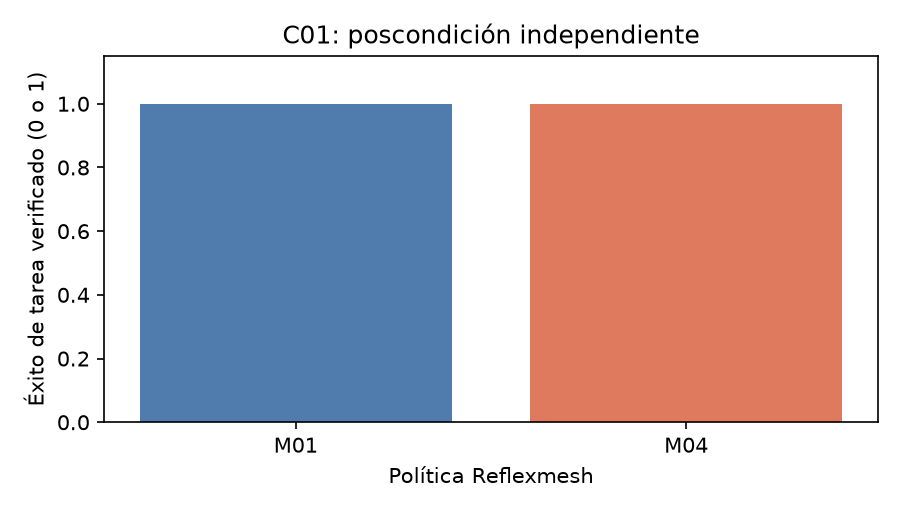

In [14]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Éxito de tarea verificado (0 o 1)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: poscondición independiente")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para el nivel 3 de evaluación y transferencia en C01, Para evaluación y transferencia, estas barras muestran resultados nuevos de poscondición de M01 y M04 en C01; Para el nivel 3 de evaluación y transferencia en C01, éxito vale 1 y falla 0. Para el nivel 3 de evaluación y transferencia en C01, Lee el caso y la semilla antes de compararlas. Para el nivel 3 de evaluación y transferencia en C01, Este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software.


## Estado del arte

En el nivel 3, para evaluación y transferencia en C01, Benchmarks de uso de herramientas como ToolSandbox, SWE-bench y tau-bench motivan condiciones con estado y herramientas cambiantes, pero Neuraxis ejecuta subconjuntos locales y no afirma reproducir un benchmark completo. En el nivel 3, para evaluación y transferencia en C01, La transferencia se mantiene separada del núcleo saturado de 14.400 episodios. En el nivel 3, para evaluación y transferencia en C01, El gráfico emparejado M01/M04 es solo una ilustración reproducible. En el nivel 3, para evaluación y transferencia en C01, En el nivel 3, para evaluación y transferencia en C01, la comparación requiere denominadores completos con hash y el carril retenido de transferencia. En el nivel 3, para evaluación y transferencia en C01, La ventaja observada de M04 describe este conjunto, no una clasificación universal.


### evaluación y transferencia · L3 — Ejecutar la referencia XGBoost bajo condiciones emparejadas

Esta llamada de referencia del nivel 3 para evaluación y transferencia ejecuta M04 en C01 con la misma semilla nominal, y su resultado y tiempo forman una observación emparejada.


In [15]:
# Execute the measured XGBoost policy on the identical case specification.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("State-of-the-art comparator runs:", 1)
print("XGBoost task success:", state_art_result["metrics"]["task_success"])


State-of-the-art comparator runs: 1
XGBoost task success: 1


### evaluación y transferencia · L3 | Tiempo registrado del controlador

En el nivel 3, la figura de tiempos de evaluación y transferencia usa registros congelados y verificados por hash para M01 y M04 en C01, no los tiempos dependientes de la máquina de episodios nuevos. Esta vista de nivel 3 para evaluación y transferencia describe el entorno registrado bajo su caso, variante y semilla declarados.

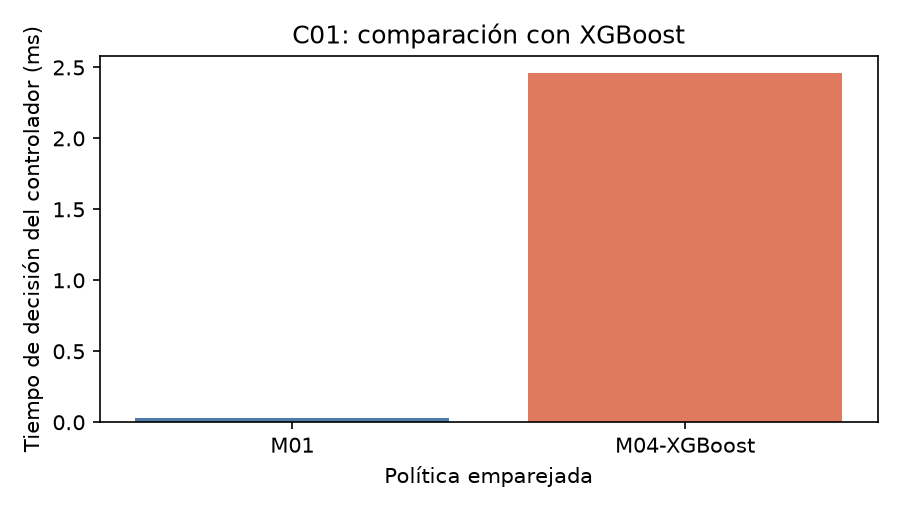

In [16]:
# Compare hash-verified canonical controller times under the same case, variant and seed.
labels = [primary_id, "M04-XGBoost"]
latencies = [records[primary_id]["metrics"]["controller_ms"], records["M04"]["metrics"]["controller_ms"]]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Tiempo de decisión del controlador (ms)")
ax.set_xlabel("Política emparejada")
ax.set_title(f"{sample_case}: comparación con XGBoost")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


La figura de nivel 3 para evaluación y transferencia lee registros canónicos de M01/M04 en C01, variante nominal y semilla 40000, luego de verificar sus hashes en la frontera de datos. En esta lección de evaluación y transferencia, el gráfico estable describe la latencia registrada y no afirma rapidez en la máquina actual.

## Resultados

**Respuesta:** La comparación de nivel 3 para evaluación y transferencia contiene 2 episodios nuevos y 1 referencia XGBoost M04 en C01; esas 3 corridas emparejadas no establecen superioridad poblacional para evaluación y transferencia.

Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, La matriz central está saturada: Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, siete métodos resuelven los 1.200 episodios y solo 71/1.440 celdas método/caso/variante cambian por semilla. Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, En transferencia estructural, M04 resuelve 24/24 casos y M12 21/24; Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, el carril semántico opaco mayor también favorece M09 frente a M12. Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, No hay respaldo para afirmar superioridad aprendida.

Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Este paso de autoría no compromete salidas generadas; Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, Para el nivel 3 de evaluación y transferencia en C01, `scripts/run_notebooks.py` las ejecuta y guarda desde un kernel nuevo.


## Resumen

Para el nivel 3 de evaluación y transferencia en C01, En el nivel 3, evaluación y transferencia usa C01 para mostrar el comportamiento del método publicado bajo una condición declarada. Para el nivel 3 de evaluación y transferencia en C01, Mantén el resultado observado separado de una afirmación sobre inteligencia general para controlar software.


## Referencias

- [TOOLSANDBOX](https://arxiv.org/abs/2408.04682)
- [SWE](https://arxiv.org/abs/2310.06770)
- [TAU2](https://arxiv.org/abs/2506.07982)
